In [3]:
import ast
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from pathlib import Path

In [4]:
def Scores_of_Single_Episode_Anime():
    """Plot score frequencies for anime with exactly one episode.
    Higher bars indicate more single-episode anime with that score."""
    animes = pd.read_csv("anime_clean.csv")
    animes[animes["episodes"] == 1.0]["score"].value_counts().reindex(range(1, 11), fill_value=0).sort_index().plot(kind="bar", xlabel="Score", ylabel="Number of Anime", title="Scores of Single-Episode Anime")

def Scores_of_Multi_Episode_Anime():
    """Plot score frequencies for anime with multiple episodes.
    Higher bars indicate more multi-episode anime with that score."""
    animes = pd.read_csv("anime_clean.csv")
    animes[animes["episodes"] > 1.0]["score"].value_counts().reindex(range(1, 11), fill_value=0).sort_index().plot(kind="bar", xlabel="Score", ylabel="Number of Anime", title="Scores of Multi-Episode Anime")
    
def Anime_Feature_Correlations():
    """Show correlations among numeric anime features.
    Values near +1/-1 indicate stronger positive/negative linear relationships; 0 indicates little linear relationship."""
    animes = pd.read_csv("anime_clean.csv")
    columns = ["episodes", "members", "popularity", "ranked", "score", "release_year", "anime_age"]
    
    corr = animes[columns].corr()
    
    plt.figure(figsize=(10, 7))
    
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, center=0)
    
    plt.title("Anime Feature Correlations")
    plt.tight_layout()
    plt.show()

def Distribution_of_Anime_Scores_by_Genre(min_samples=30):
    """Compare anime score distributions across genres with enough samples.
    Box centers show medians; boxes show middle halves, and points beyond whiskers may be outliers."""
    animes = pd.read_csv("anime_clean.csv")

    animes["genre"] = animes["genre"].apply(ast.literal_eval)
    animes["score"] = pd.to_numeric(animes["score"], errors="coerce")

    genre_dataframe = animes[["genre", "score"]].explode(
        "genre", ignore_index=True
    )

    genre_dataframe = genre_dataframe.dropna(subset=["genre", "score"])

    # Count anime in each genre
    genre_counts = genre_dataframe.groupby("genre")["score"].count()

    # Exclude genres with insufficient observations
    valid_genres = genre_counts[genre_counts >= min_samples].index

    genre_dataframe = genre_dataframe[
        genre_dataframe["genre"].isin(valid_genres)
    ]

    # Order genres by median score
    genre_order = (
        genre_dataframe.groupby("genre")["score"]
        .median()
        .sort_values(ascending=False)
        .index
    )

    fig, ax = plt.subplots(figsize=(16, 8), layout="constrained")

    sns.boxplot(
        data=genre_dataframe,
        x="genre",
        y="score",
        order=genre_order,
        ax=ax
    )

    ax.tick_params(axis="x", labelrotation=90)

    ax.set_title("Distribution of Anime Scores by Genre")
    ax.set_xlabel("Genre")
    ax.set_ylabel("Anime Score")

    plt.show()
    
def Distribution_of_Anime_Ranks_by_Genre(min_samples=30):
    """Compare anime ranking distributions across genres with enough samples.
    Lower rank numbers are better; boxes summarize each genre’s spread and median."""
    animes = pd.read_csv("anime_clean.csv")

    animes["genre"] = animes["genre"].apply(ast.literal_eval)
    animes["ranked"] = pd.to_numeric(animes["ranked"], errors="coerce")

    genre_dataframe = animes[["genre", "ranked"]].explode(
        "genre", ignore_index=True
    )

    genre_dataframe = genre_dataframe.dropna(subset=["genre", "ranked"])

    # Count anime in each genre
    genre_counts = genre_dataframe.groupby("genre")["ranked"].count()

    # Exclude genres with insufficient observations
    valid_genres = genre_counts[genre_counts >= min_samples].index

    genre_dataframe = genre_dataframe[
        genre_dataframe["genre"].isin(valid_genres)
    ]

    # Order genres by median rank (lower is better)
    genre_order = (
        genre_dataframe.groupby("genre")["ranked"]
        .median()
        .sort_values()
        .index
    )

    fig, ax = plt.subplots(figsize=(16, 8), layout="constrained")

    sns.boxplot(
        data=genre_dataframe,
        x="genre",
        y="ranked",
        order=genre_order,
        ax=ax
    )

    ax.invert_yaxis()
    ax.tick_params(axis="x", labelrotation=90)

    ax.set_title("Distribution of Anime Ranks by Genre")
    ax.set_xlabel("Genre")
    ax.set_ylabel("Anime Rank")

    plt.show()

def Distribution_of_Anime_Scores():

    """Plot the overall distribution of anime scores.
    Taller bins indicate more anime in that score range; the curve smooths the distribution."""
    animes = pd.read_csv("anime_clean.csv")
    plt.figure(figsize=(10, 6))
    
    sns.histplot(data=animes, x="score", bins=20, kde=True)
    
    plt.title("Distribution of Anime Scores")
    plt.xlabel("Anime Score")
    plt.ylabel("Frequency")
    
    plt.show()

def Anime_Genre_Frequency():

    """Count how many anime are assigned to each genre.
    Taller bars represent genres appearing in more anime; titles can belong to multiple genres."""
    animes = pd.read_csv("anime_clean.csv")
    # Convert genre strings into Python lists
    animes["genre"] = animes["genre"].apply(ast.literal_eval)
    genre_types = animes["genre"].explode(ignore_index=True)
    genre_types = dict.fromkeys(genre_types)
    for genre in genre_types.keys():
        genre_types[genre] = animes["genre"].apply(lambda x: isinstance(x, list) and genre in x).sum()
    
    
    genre_counts = pd.Series(genre_types)
    genre_counts = genre_counts[genre_counts.index.notna()].sort_values(ascending=False)
    
    plt.figure(figsize=(16, 7))
    
    plt.bar(genre_counts.index, genre_counts.values)
    
    plt.xticks(rotation=90)
    plt.xlabel("Genre")
    plt.ylabel("Frequency")
    plt.title("Anime Genre Frequency")
    
    plt.tight_layout()
    plt.show()

In [5]:
def combine_json_files(input_dir: str, output_file: str):
    """Combine dictionary entries from JSON files in a directory into one output file.
    When keys repeat, values from later files replace earlier ones."""
    combined = {}

    for file in sorted(Path(input_dir).glob("*.json")):
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        if not isinstance(data, dict):
            raise TypeError(f"{file} does not contain a dictionary")

        combined.update(data)

    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(combined, f, indent=4, ensure_ascii=False)

    return combined

In [6]:
def Number_of_Reviews_per_Anime_uid():
    """Scatter-plot review counts against anime IDs.
    Higher points indicate more reviews; anime IDs are identifiers, not a continuous measure."""
    anime_df = pd.read_csv("anime_review_counts.csv")
    
    plt.figure(figsize=(14, 7))
    
    sns.scatterplot(
        data=anime_df,
        x="anime_uid",
        y="review_count",
        alpha=0.5,
        s=20
    )
    
    plt.title("Number of Reviews per Anime")
    plt.xlabel("Anime UID")
    plt.ylabel("Review Count")
    
    plt.tight_layout()
    plt.show()

In [7]:
def Top_30_Most_Reviewed_Anime():
    """Plot the 30 anime with the largest review counts.
    Taller bars identify anime with more reviews, not necessarily higher ratings."""
    anime_df = pd.read_csv("anime_review_counts.csv")
    animes = pd.read_csv("anime_clean.csv")
    
    # Get the 30 most reviewed anime
    top_anime = anime_df.nlargest(30, "review_count")
    
    # Match anime IDs with their titles
    top_anime = top_anime.merge(
        animes[["uid", "title"]],
        left_on="anime_uid",
        right_on="uid",
        how="left",
        validate="many_to_one"
    )
    
    # Create plot
    fig, ax = plt.subplots(figsize=(16, 8), layout="constrained")
    
    sns.barplot(
        data=top_anime,
        x="title",
        y="review_count",
        order=top_anime["title"],
        ax=ax
    )
    
    ax.tick_params(axis="x", labelrotation=90)
    
    ax.set_title("Top 30 Most Reviewed Anime")
    ax.set_xlabel("Anime")
    ax.set_ylabel("Number of Reviews")
    
    plt.show()

In [8]:
def Anime_Sentiment_Top_30_Polarity():
    """Compare mean Lexicon and TextBlob polarity for the 30 most-reviewed anime.
    Negative values indicate negative sentiment, positive values positive sentiment, and zero neutrality."""
    animes = pd.read_csv("anime_clean.csv")

    # Calculate average sentiment and review counts
    anime_sentiment = sentiment_df.groupby("anime_uid").agg(
        review_count=("uid", "count"),
        lexicon_polarity=("lexicon_polarity", "mean"),
        textblob_polarity=("textblob_polarity", "mean"),
        textblob_subjectivity=("textblob_subjectivity", "mean")
    ).reset_index()

    # Select 30 most-reviewed anime
    top_anime = anime_sentiment.nlargest(30, "review_count")

    # Match anime IDs with titles
    top_anime = top_anime.merge(
        animes[["uid", "title"]],
        left_on="anime_uid",
        right_on="uid",
        how="left",
        validate="many_to_one"
    )

    top_anime["title"] = top_anime["title"].fillna(
        top_anime["anime_uid"].astype(str)
    )

    # Reshape for plotting
    plot_df = top_anime.melt(
        id_vars=["anime_uid", "title"],
        value_vars=["lexicon_polarity", "textblob_polarity"],
        var_name="Method",
        value_name="Average Polarity"
    )

    fig, ax = plt.subplots(figsize=(16, 10), layout="constrained")

    sns.barplot(
        data=plot_df,
        y="title",
        x="Average Polarity",
        hue="Method",
        order=top_anime["title"],
        ax=ax
    )

    ax.axvline(0, color="black", linewidth=1)

    ax.set_title("Average Review Sentiment for the 30 Most-Reviewed Anime")
    ax.set_xlabel("Average Sentiment Polarity")
    ax.set_ylabel("Anime")

    plt.show()

In [9]:
def Anime_Subjectivity_Top_30():
    """Plot mean TextBlob subjectivity for the 30 most-reviewed anime.
    Values near 0 suggest more objective language; values near 1 suggest more subjective language."""
    with open("sentiment_results.json", "r", encoding="utf-8") as f:
        data = json.load(f)

    records = []

    for key, values in data.items():
        uid, anime_uid = map(int, key.split(","))

        records.append({
            "uid": uid,
            "anime_uid": anime_uid,
            "subjectivity": values.get("textblob_subjectivity")
        })

    sentiment_df = pd.DataFrame(records)
    sentiment_df["subjectivity"] = pd.to_numeric(
        sentiment_df["subjectivity"], errors="coerce"
    )

    animes = pd.read_csv("anime_clean.csv")

    # Calculate average subjectivity and review count
    anime_subjectivity = sentiment_df.groupby("anime_uid").agg(
        review_count=("subjectivity", "count"),
        average_subjectivity=("subjectivity", "mean")
    ).reset_index()

    # Select 30 most-reviewed anime
    top_anime = anime_subjectivity.nlargest(30, "review_count")

    # Match anime IDs with titles
    top_anime = top_anime.merge(
        animes[["uid", "title"]],
        left_on="anime_uid",
        right_on="uid",
        how="left",
        validate="many_to_one"
    )

    top_anime["title"] = top_anime["title"].fillna(
        top_anime["anime_uid"].astype(str)
    )

    # Sort by average subjectivity
    top_anime = top_anime.sort_values(
        "average_subjectivity", ascending=False
    )

    fig, ax = plt.subplots(figsize=(14, 12), layout="constrained")

    sns.barplot(
        data=top_anime,
        y="title",
        x="average_subjectivity",
        order=top_anime["title"],
        ax=ax
    )

    ax.set_xlim(0, 1)
    ax.set_title("Average Review Subjectivity by Anime")
    ax.set_xlabel("Average TextBlob Subjectivity")
    ax.set_ylabel("Anime")

    plt.show()

In [10]:
def Anime_Subjectivity_vs_Polarity_Top_30():
    """Compare subjectivity and two polarity methods for the 30 most-reviewed anime.
    Blue bars show subjectivity (0–1); polarity bars show sentiment direction and strength (-1 to 1)."""
    with open("sentiment_results.json", "r", encoding="utf-8") as f:
        data = json.load(f)

    records = []

    for key, values in data.items():
        uid, anime_uid = map(int, key.split(","))

        records.append({
            "uid": uid,
            "anime_uid": anime_uid,
            "lexicon_polarity": values.get("lexicon_polarity"),
            "textblob_polarity": values.get("textblob_polarity"),
            "textblob_subjectivity": values.get("textblob_subjectivity")
        })

    sentiment_df = pd.DataFrame(records)

    # Convert sentiment measurements to numeric values
    columns = [
        "lexicon_polarity",
        "textblob_polarity",
        "textblob_subjectivity"
    ]

    sentiment_df[columns] = sentiment_df[columns].apply(
        pd.to_numeric, errors="coerce"
    )

    # Calculate average sentiment measurements for each anime
    anime_sentiment = sentiment_df.groupby("anime_uid").agg(
        review_count=("uid", "count"),
        lexicon_polarity=("lexicon_polarity", "mean"),
        textblob_polarity=("textblob_polarity", "mean"),
        textblob_subjectivity=("textblob_subjectivity", "mean")
    ).reset_index()

    # Select the 30 most-reviewed anime
    top_anime = anime_sentiment.nlargest(30, "review_count").copy()

    # Load anime titles
    animes = pd.read_csv("anime_clean.csv")

    top_anime = top_anime.merge(
        animes[["uid", "title"]],
        left_on="anime_uid",
        right_on="uid",
        how="left",
        validate="many_to_one"
    )

    top_anime["title"] = top_anime["title"].fillna(
        top_anime["anime_uid"].astype(str)
    )

    # Sort by subjectivity
    top_anime = top_anime.sort_values(
        "textblob_subjectivity",
        ascending=False
    )

    # Prepare plotting values
    y = np.arange(len(top_anime))

    subjectivity = top_anime["textblob_subjectivity"].to_numpy()
    lexicon = top_anime["lexicon_polarity"].to_numpy()
    textblob = top_anime["textblob_polarity"].to_numpy()

    # Determine polarity colors
    lexicon_colors = [
        "seagreen" if value >= 0 else "indianred"
        for value in lexicon
    ]

    textblob_colors = [
        "mediumseagreen" if value >= 0 else "lightcoral"
        for value in textblob
    ]

    # Create two side-by-side graphs
    fig, axes = plt.subplots(
        1, 2,
        figsize=(22, 12),
        layout="constrained",
        sharey=True
    )

    # Left graph: Subjectivity
    axes[0].barh(
        y,
        subjectivity,
        height=0.65,
        color="steelblue"
    )

    axes[0].set_xlim(0, 1)
    axes[0].set_title("Average Review Subjectivity")
    axes[0].set_xlabel("Subjectivity")
    axes[0].set_ylabel("Anime")

    # Right graph: Polarity
    bar_height = 0.35

    # Lexicon polarity
    axes[1].barh(
        y - bar_height / 2,
        lexicon,
        height=bar_height,
        color=lexicon_colors
    )

    # TextBlob polarity
    axes[1].barh(
        y + bar_height / 2,
        textblob,
        height=bar_height,
        color=textblob_colors
    )

    axes[1].set_xlim(-1, 1)
    axes[1].axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    axes[1].set_title("Average Review Polarity")
    axes[1].set_xlabel("Polarity")
    axes[1].set_ylabel("")

    # Anime labels
    axes[0].set_yticks(y)
    axes[0].set_yticklabels(top_anime["title"])

    # Highest subjectivity at the top
    axes[0].invert_yaxis()

    # Custom legend
    axes[1].legend(handles=[
        Patch(color="seagreen", label="Lexicon Positive"),
        Patch(color="indianred", label="Lexicon Negative"),
        Patch(color="mediumseagreen", label="TextBlob Positive"),
        Patch(color="lightcoral", label="TextBlob Negative")
    ], title="Sentiment Method", loc="lower right")

    # Grid
    axes[0].grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    axes[1].grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    fig.suptitle(
        "Subjectivity vs Polarity for the 30 Most-Reviewed Anime",
        fontsize=16
    )

    plt.show()

In [11]:



def Anime_Mirrored_Bar_Chart():
    # Load sentiment results
    """Mirror average subjectivity against Lexicon and TextBlob polarity magnitudes.
    Blue extends left for subjectivity; rightward bar lengths show absolute polarity, with color indicating sentiment sign."""
    with open("sentiment_results.json", "r", encoding="utf-8") as f:
        data = json.load(f)

    records = []

    for key, values in data.items():
        uid, anime_uid = map(int, key.split(","))

        records.append({
            "uid": uid,
            "anime_uid": anime_uid,
            "lexicon_polarity": values.get("lexicon_polarity"),
            "textblob_polarity": values.get("textblob_polarity"),
            "subjectivity": values.get("textblob_subjectivity")
        })

    df = pd.DataFrame(records)

    # Convert sentiment values to numeric
    columns = [
        "lexicon_polarity",
        "textblob_polarity",
        "subjectivity"
    ]

    df[columns] = df[columns].apply(pd.to_numeric, errors="coerce")

    # Calculate averages for each anime
    anime_df = df.groupby("anime_uid").agg(
        review_count=("uid", "count"),
        lexicon_polarity=("lexicon_polarity", "mean"),
        textblob_polarity=("textblob_polarity", "mean"),
        subjectivity=("subjectivity", "mean")
    ).reset_index()

    # Select 30 most-reviewed anime
    top_anime = anime_df.nlargest(30, "review_count").copy()

    # Load anime titles
    animes = pd.read_csv("anime_clean.csv")

    top_anime = top_anime.merge(
        animes[["uid", "title"]],
        left_on="anime_uid",
        right_on="uid",
        how="left",
        validate="many_to_one"
    )

    top_anime["title"] = top_anime["title"].fillna(
        top_anime["anime_uid"].astype(str)
    )

    # Sort by subjectivity
    top_anime = top_anime.sort_values("subjectivity")

    # Prepare plotting values
    subjectivity = top_anime["subjectivity"].to_numpy()
    lexicon = top_anime["lexicon_polarity"].to_numpy()
    textblob = top_anime["textblob_polarity"].to_numpy()

    # Determine polarity colors
    lexicon_colors = [
        "seagreen" if value >= 0 else "indianred"
        for value in lexicon
    ]

    textblob_colors = [
        "mediumseagreen" if value >= 0 else "lightcoral"
        for value in textblob
    ]

    # Create mirrored bar chart
    fig, ax = plt.subplots(
        figsize=(17, 13),
        layout="constrained"
    )

    y = np.arange(len(top_anime))

    # Subjectivity extends left
    ax.barh(
        y,
        -subjectivity,
        height=0.65,
        color="steelblue",
        label="Subjectivity"
    )

    # Lexicon polarity extends right
    ax.barh(
        y + 0.17,
        np.abs(lexicon),
        height=0.30,
        color=lexicon_colors,
        label="Lexicon Polarity"
    )

    # TextBlob polarity extends right
    ax.barh(
        y - 0.17,
        np.abs(textblob),
        height=0.30,
        color=textblob_colors,
        label="TextBlob Polarity"
    )

    # Center line
    ax.axvline(
        0,
        color="black",
        linewidth=1.5
    )

    # Anime labels
    ax.set_yticks(y)
    ax.set_yticklabels(top_anime["title"])

    # Symmetric axis
    ax.set_xlim(-1, 1)

    ticks = np.arange(-1, 1.01, 0.25)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{abs(tick):.2f}" for tick in ticks])

    ax.set_title(
        "Average Subjectivity vs Lexicon and TextBlob Polarity by Anime",
        fontsize=15
    )

    ax.set_xlabel(
        "← Subjectivity                  Polarity Magnitude →"
    )

    ax.set_ylabel("Anime")

    # Custom legend
    ax.legend(handles=[
        Patch(color="steelblue", label="Subjectivity"),
        Patch(color="seagreen", label="Lexicon Positive"),
        Patch(color="indianred", label="Lexicon Negative"),
        Patch(color="mediumseagreen", label="TextBlob Positive"),
        Patch(color="lightcoral", label="TextBlob Negative")
    ], loc="lower right")

    plt.show()

In [12]:


def Anime_Genre_Polarity_Top_30():
    # Load sentiment results
    """Compare Lexicon and TextBlob polarity for 30 genres ranked by their combined mean.
    Bars right of zero are positive and left are negative; each review contributes to all its anime’s genres."""
    with open("sentiment_results.json", "r", encoding="utf-8") as f:
        data = json.load(f)

    records = []

    for key, values in data.items():
        uid, anime_uid = map(int, key.split(","))

        records.append({
            "review_uid": uid,
            "anime_uid": anime_uid,
            "lexicon_polarity": values.get("lexicon_polarity"),
            "textblob_polarity": values.get("textblob_polarity")
        })

    sentiment_df = pd.DataFrame(records)

    columns = ["lexicon_polarity", "textblob_polarity"]

    sentiment_df[columns] = sentiment_df[columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Load anime data
    animes = pd.read_csv("anime_clean.csv")

    # Convert genre strings to lists
    def parse_genres(value):
        """Convert a genre field into a list of genre names.
        Return an empty list for missing values and split comma-separated strings when needed."""
        if isinstance(value, list):
            return value

        if pd.isna(value):
            return []

        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, (list, tuple, set)):
                return list(parsed)
        except (ValueError, SyntaxError, TypeError):
            pass

        return [
            genre.strip()
            for genre in str(value).split(",")
            if genre.strip()
        ]

    animes["genre"] = animes["genre"].apply(parse_genres)

    # Match anime IDs with their genres
    genre_df = sentiment_df.merge(
        animes[["uid", "genre"]],
        left_on="anime_uid",
        right_on="uid",
        how="inner",
        validate="many_to_one"
    )

    # Expand genres
    genre_df = genre_df.explode("genre", ignore_index=True)

    genre_df = genre_df.dropna(subset=["genre"]).copy()

    genre_df["genre"] = genre_df["genre"].astype(str).str.strip()

    genre_df = genre_df[genre_df["genre"] != ""]

    # Calculate average polarity for each genre
    genre_sentiment = genre_df.groupby("genre").agg(
        review_count=("review_uid", "count"),
        lexicon_polarity=("lexicon_polarity", "mean"),
        textblob_polarity=("textblob_polarity", "mean")
    ).reset_index()

    # Calculate combined polarity for ranking only
    genre_sentiment["combined_polarity"] = (
        genre_sentiment["lexicon_polarity"] +
        genre_sentiment["textblob_polarity"]
    ) / 2

    # Select top 30 genres
    top_genres = genre_sentiment.nlargest(
        30,
        "combined_polarity"
    ).sort_values("combined_polarity")

        # Prepare plotting values
    y = np.arange(len(top_genres))

    lexicon = top_genres["lexicon_polarity"].to_numpy()
    textblob = top_genres["textblob_polarity"].to_numpy()

    # Determine polarity colors
    lexicon_colors = [
        "seagreen" if value >= 0 else "indianred"
        for value in lexicon
    ]

    textblob_colors = [
        "mediumseagreen" if value >= 0 else "lightcoral"
        for value in textblob
    ]

    # Create chart
    fig, ax = plt.subplots(
        figsize=(15, 12),
        layout="constrained"
    )

    bar_height = 0.35

    # Lexicon polarity
    ax.barh(
        y - bar_height / 2,
        lexicon,
        height=bar_height,
        color=lexicon_colors
    )

    # TextBlob polarity
    ax.barh(
        y + bar_height / 2,
        textblob,
        height=bar_height,
        color=textblob_colors
    )

    # Center line
    ax.axvline(
        0,
        color="black",
        linewidth=1.5
    )

    # Genre labels
    ax.set_yticks(y)
    ax.set_yticklabels(top_genres["genre"])

    # Polarity axis
    ax.set_xlim(-1, 1)
    ax.set_xticks(np.arange(-1, 1.01, 0.25))

    ax.set_xlabel("Average Polarity")
    ax.set_ylabel("Anime Genre")

    ax.set_title(
        "Top 30 Anime Genres by Average Sentiment Polarity",
        fontsize=15
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    # Custom legend matching Anime_Mirrored_Bar_Chart
    ax.legend(handles=[
        Patch(color="seagreen", label="Lexicon Positive"),
        Patch(color="indianred", label="Lexicon Negative"),
        Patch(color="mediumseagreen", label="TextBlob Positive"),
        Patch(color="lightcoral", label="TextBlob Negative")
    ], loc="lower right")

    plt.show()

## Relationship visualizations

Existing: **Genre and audience scores** — `Distribution_of_Anime_Scores_by_Genre()`. The following functions add dedicated plots for the other four requested relationships.

In [13]:
def Rating_vs_Popularity():
    """Compare anime ratings with popularity rank and audience size.
    Lower popularity ranks mean greater popularity; an upward rating trend with members
    suggests more widely followed anime tend to receive higher scores."""
    animes = pd.read_csv("anime_clean.csv")
    for column in ["score", "popularity", "members"]:
        animes[column] = pd.to_numeric(animes[column], errors="coerce")
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
    sns.regplot(data=animes.dropna(subset=["score", "popularity"]), x="popularity", y="score",
                scatter_kws={"alpha": 0.15, "s": 12}, line_kws={"color": "indianred"}, ax=axes[0])
    axes[0].set(title="Rating vs Popularity Rank", xlabel="Popularity Rank (lower = more popular)", ylabel="Anime Score")
    members = animes.dropna(subset=["score", "members"]).query("members > 0")
    sns.regplot(data=members.assign(log_members=np.log10(members["members"])), x="log_members", y="score",
                scatter_kws={"alpha": 0.15, "s": 12}, line_kws={"color": "indianred"}, ax=axes[1])
    axes[1].set(title="Rating vs Audience Size", xlabel="Log10(Member Count)", ylabel="Anime Score")
    plt.show()


def Episode_Count_vs_Ratings():
    """Plot episode count against anime score, using a log-scaled episode axis.
    The trend shows whether longer series generally have higher or lower ratings;
    each point represents an anime, not an individual episode."""
    animes = pd.read_csv("anime_clean.csv")
    for column in ["episodes", "score"]:
        animes[column] = pd.to_numeric(animes[column], errors="coerce")
    plot_df = animes.dropna(subset=["episodes", "score"]).query("episodes > 0").copy()
    plot_df["log_episodes"] = np.log10(plot_df["episodes"])
    fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
    sns.regplot(data=plot_df, x="log_episodes", y="score",
                scatter_kws={"alpha": 0.2, "s": 15}, line_kws={"color": "indianred"}, ax=ax)
    ticks = [1, 2, 5, 10, 25, 50, 100, 250, 500, 1000]
    ticks = [v for v in ticks if v <= plot_df["episodes"].max()]
    ax.set_xticks(np.log10(ticks), [str(v) for v in ticks])
    ax.set(title="Episode Count vs Anime Rating", xlabel="Number of Episodes (log scale)", ylabel="Anime Score")
    plt.show()


def Popularity_vs_Review_Volume():
    """Compare popularity rank and audience size with review volume.
    Lower popularity ranks and larger member counts generally suggest greater reach;
    review counts measure activity, not how positive the reviews are."""
    animes = pd.read_csv("anime_clean.csv")
    counts = pd.read_csv("anime_review_counts.csv")
    plot_df = counts.merge(animes[["uid", "popularity", "members"]], left_on="anime_uid", right_on="uid",
                           how="inner", validate="many_to_one")
    for column in ["popularity", "members", "review_count"]:
        plot_df[column] = pd.to_numeric(plot_df[column], errors="coerce")
    plot_df = plot_df.dropna(subset=["popularity", "members", "review_count"])
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
    sns.scatterplot(data=plot_df, x="popularity", y="review_count", alpha=0.4, s=25, ax=axes[0])
    axes[0].set(title="Popularity Rank vs Review Count", xlabel="Popularity Rank (lower = more popular)", ylabel="Number of Reviews")
    sns.scatterplot(data=plot_df, x="members", y="review_count", alpha=0.4, s=25, ax=axes[1])
    axes[1].set(title="Audience Size vs Review Count", xlabel="Member Count", ylabel="Number of Reviews")
    if (plot_df["members"] > 0).all():
        axes[1].set_xscale("log")
    plt.show()


def Review_Sentiment_vs_Ratings():
    """Compare each anime's average Lexicon and TextBlob review polarity with its score.
    An upward trend means higher-rated anime tend to receive more positive reviews;
    separate panels reveal whether the two sentiment methods agree."""
    with open("sentiment_results.json", "r", encoding="utf-8") as f:
        results = json.load(f)
    records = []
    for key, values in results.items():
        anime_uid = int(key.split(",")[1].strip())
        records.append({"anime_uid": anime_uid,
                        "lexicon_polarity": values.get("lexicon_polarity"),
                        "textblob_polarity": values.get("textblob_polarity")})
    sentiment = pd.DataFrame(records)
    for column in ["lexicon_polarity", "textblob_polarity"]:
        sentiment[column] = pd.to_numeric(sentiment[column], errors="coerce")
    averages = sentiment.groupby("anime_uid", as_index=False)[["lexicon_polarity", "textblob_polarity"]].mean()
    animes = pd.read_csv("anime_clean.csv")
    animes["score"] = pd.to_numeric(animes["score"], errors="coerce")
    plot_df = averages.merge(animes[["uid", "score"]], left_on="anime_uid", right_on="uid",
                             how="inner", validate="many_to_one")
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained", sharey=True)
    for ax, column, title, color in zip(axes,
            ["lexicon_polarity", "textblob_polarity"],
            ["Lexicon Polarity vs Rating", "TextBlob Polarity vs Rating"],
            ["seagreen", "mediumseagreen"]):
        sns.regplot(data=plot_df.dropna(subset=[column, "score"]), x=column, y="score",
                    scatter_kws={"alpha": 0.3, "s": 20, "color": color},
                    line_kws={"color": "indianred"}, ax=ax)
        ax.axvline(0, color="gray", linestyle="--", linewidth=1)
        ax.set(title=title, xlabel="Average Review Polarity (-1 to +1)", ylabel="Anime Score")
        ax.set_xlim(-1, 1)
    plt.show()


In [14]:
# Run these after placing the CSV/JSON data files alongside the notebook:
# Rating_vs_Popularity()
# Distribution_of_Anime_Scores_by_Genre()
# Episode_Count_vs_Ratings()
# Popularity_vs_Review_Volume()
# Review_Sentiment_vs_Ratings()

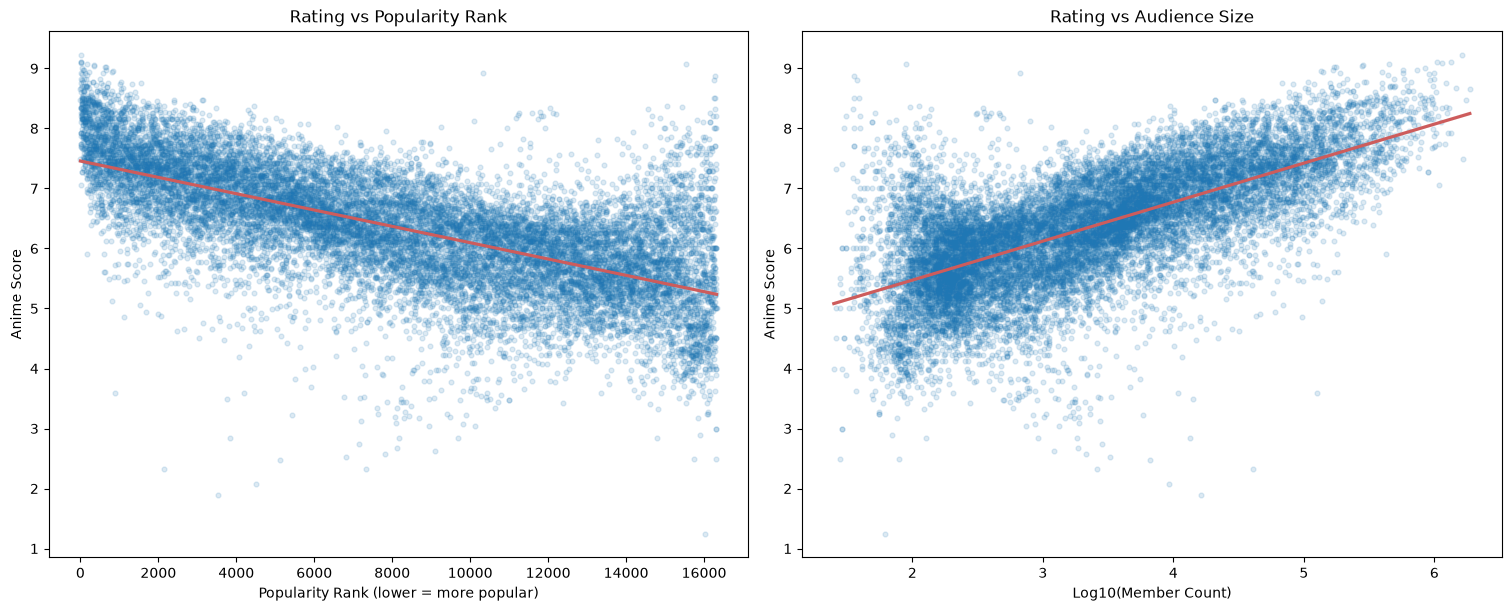

In [15]:
Rating_vs_Popularity()

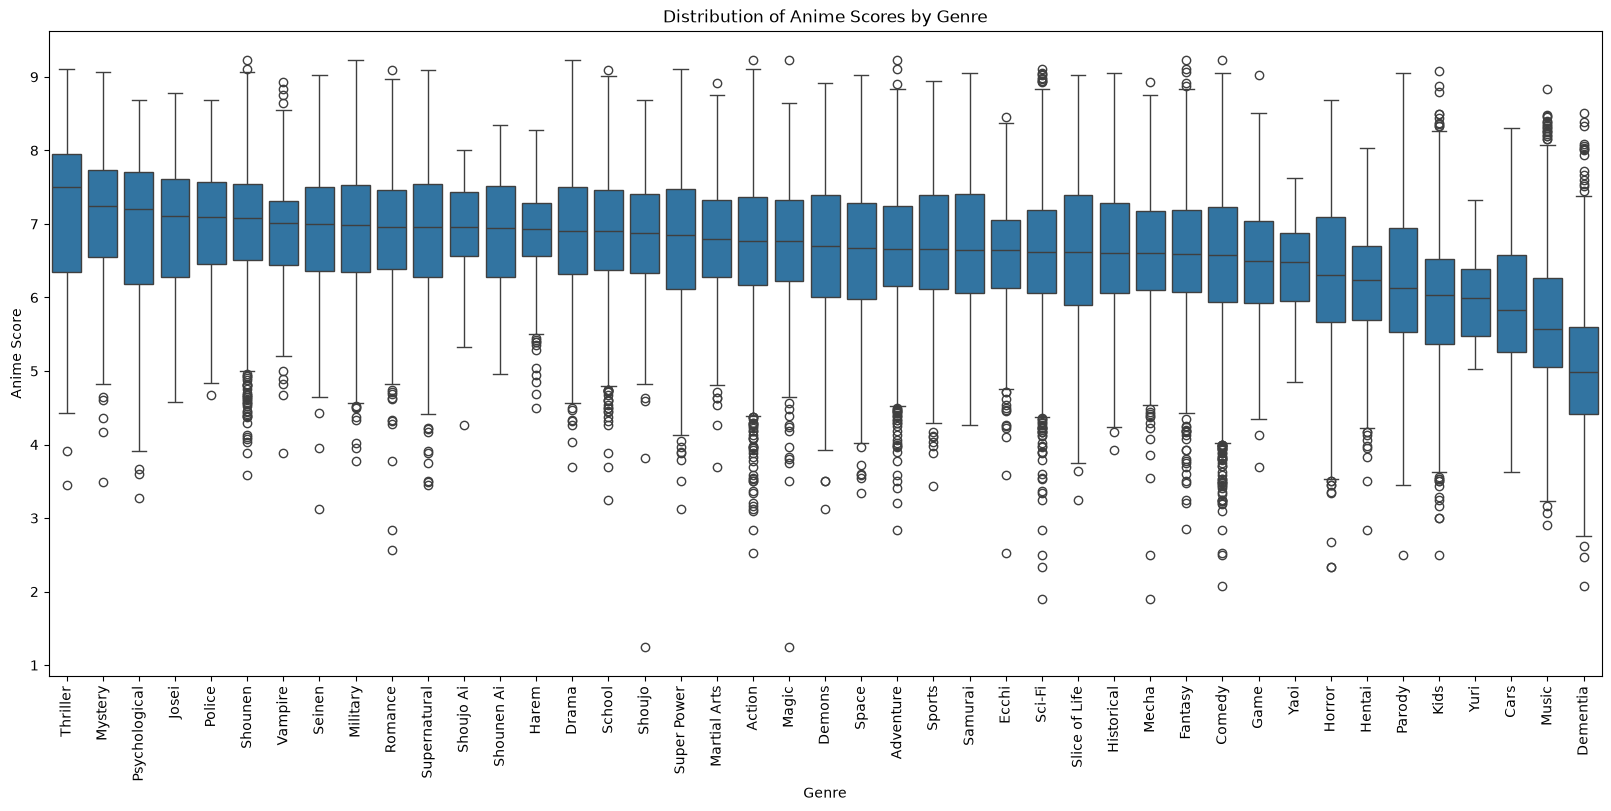

In [16]:
Distribution_of_Anime_Scores_by_Genre()

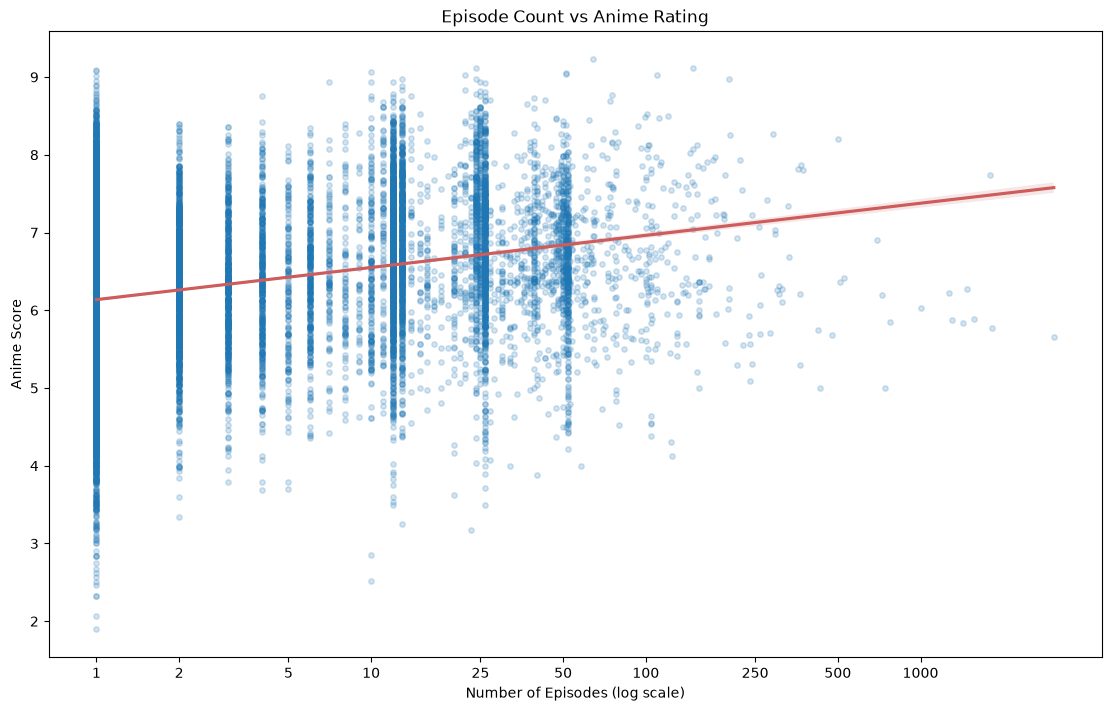

In [17]:
Episode_Count_vs_Ratings()

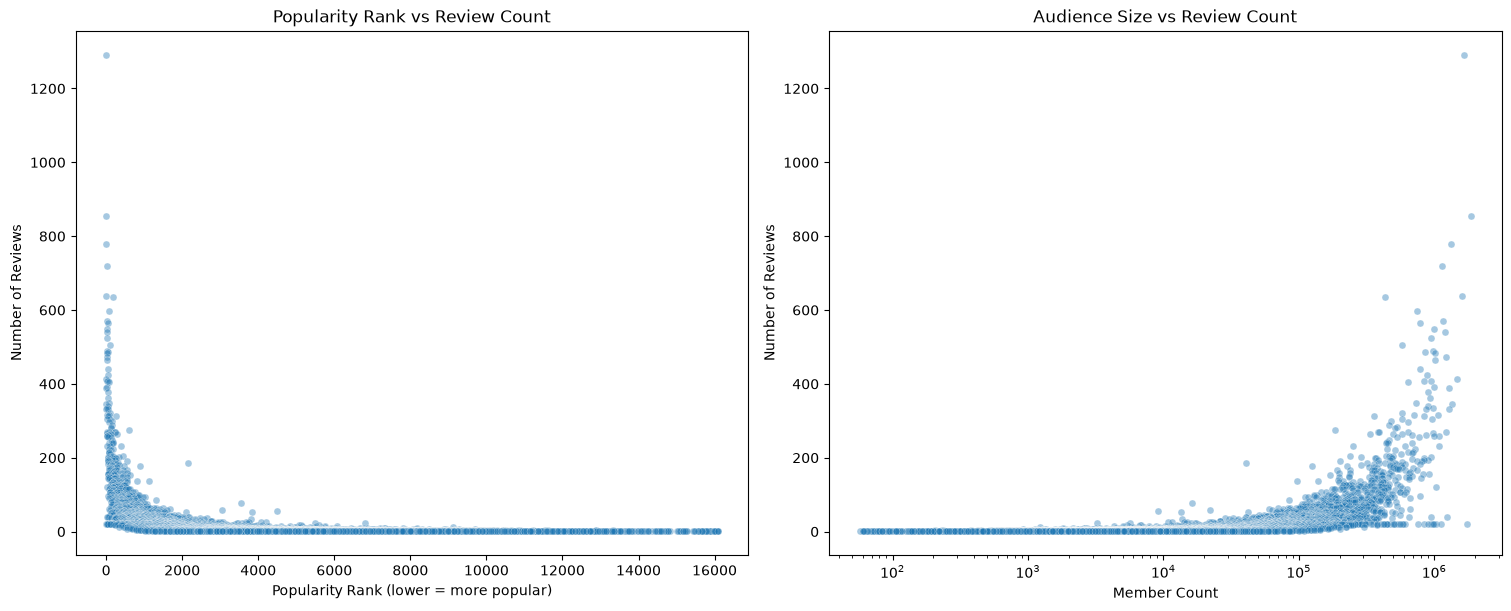

In [18]:
Popularity_vs_Review_Volume()

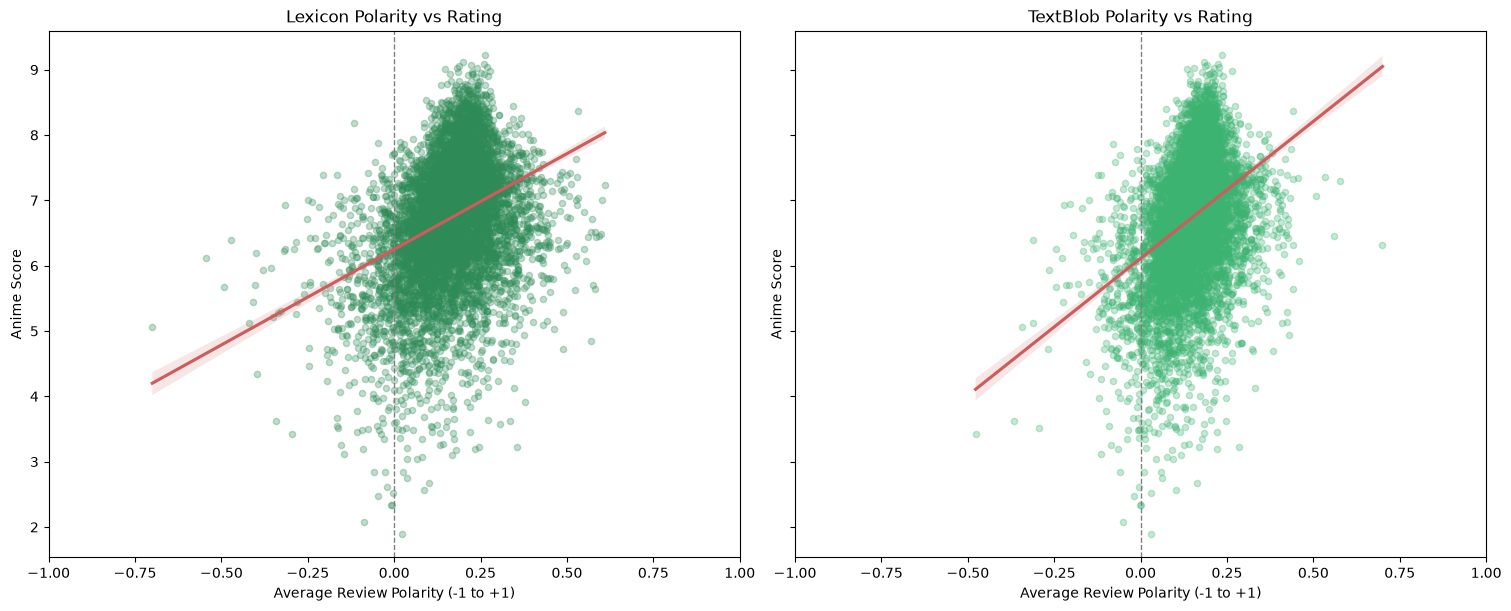

In [19]:
Review_Sentiment_vs_Ratings()